# 1. Load the Telco Customer Churn dataset

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, roc_curve, ConfusionMatrixDisplay
from xgboost import XGBClassifier
from imblearn.over_sampling import SMOTE

In [4]:
url = 'https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv'
df = pd.read_csv(url)
if 'customerID' in df.columns:
    df.drop('customerID', axis=1, inplace=True)

# 2. Convert TotalCharges to numeric and handle nulls

In [5]:
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
df.dropna(subset=['TotalCharges'], inplace=True)

In [6]:
df['Churn'] = df['Churn'].map({'Yes': 1, 'No': 0})

X = df.drop('Churn', axis=1)
y = df['Churn']

In [7]:
num_cols = X.select_dtypes(include=['int64', 'float64']).columns.tolist()
cat_cols = X.select_dtypes(include=['object']).columns.tolist()

In [8]:
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_cols),
        ('cat', OneHotEncoder(drop='first', handle_unknown='ignore'), cat_cols)
    ])

In [9]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

# 3. Balance target classes using SMOTE or scale_pos_weight

In [10]:
smote = SMOTE(random_state=42)
X_train_sm, y_train_sm = smote.fit_resample(X_train_processed, y_train)

print("Original Training Classes:\n", y_train.value_counts())
print("\nBalanced Training Classes (SMOTE):\n", y_train_sm.value_counts())

Original Training Classes:
 Churn
0    4130
1    1495
Name: count, dtype: int64

Balanced Training Classes (SMOTE):
 Churn
0    4130
1    4130
Name: count, dtype: int64


# 4. Train RandomForestClassifier and XGBClassifier with cross-validation

In [11]:
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
xgb_model = XGBClassifier(use_label_encoder=False, eval_metric='logloss', random_state=42)

In [13]:
rf_cv = cross_val_score(rf_model, X_train_sm, y_train_sm, cv=5, scoring='roc_auc')
xgb_cv = cross_val_score(xgb_model, X_train_sm, y_train_sm, cv=5, scoring='roc_auc')
print(f"Random Forest CV ROC-AUC Score: {rf_cv.mean():.4f}")
print(f"XGBoost CV ROC-AUC Score: {xgb_cv.mean():.4f}")

/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning: [16:43:11] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning: [16:43:14] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning: [16:43:17] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning: [16:43:18] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
/usr/local/lib/python3.13/dist-packages/xgboost/training.py:

Random Forest CV ROC-AUC Score: 0.9334
XGBoost CV ROC-AUC Score: 0.9336


In [14]:
rf_model.fit(X_train_sm, y_train_sm)
xgb_model.fit(X_train_sm, y_train_sm)

/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning: [16:44:02] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=None, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=None, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=None, n_jobs=None,
              num_parallel_tree=None, ...)

# 5. Plot ROC-AUC curves and extract top 10 most influential feature importances

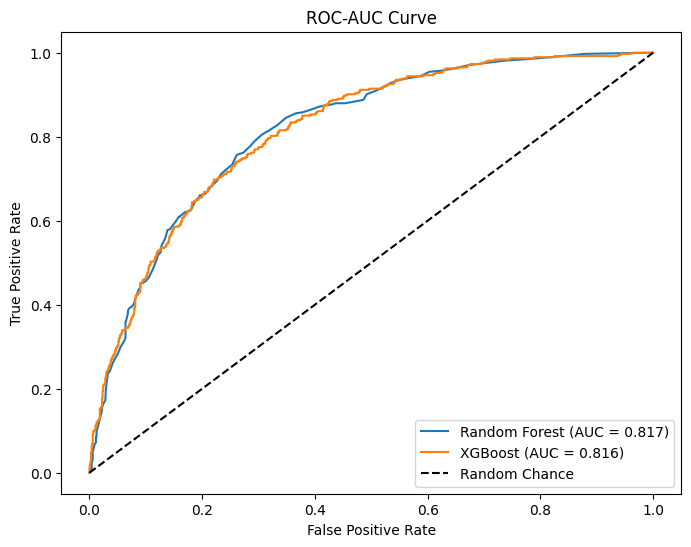

In [15]:
# --- 1. ROC-AUC Curves ---
rf_probs = rf_model.predict_proba(X_test_processed)[:, 1]
xgb_probs = xgb_model.predict_proba(X_test_processed)[:, 1]

rf_auc = roc_auc_score(y_test, rf_probs)
xgb_auc = roc_auc_score(y_test, xgb_probs)

rf_fpr, rf_tpr, _ = roc_curve(y_test, rf_probs)
xgb_fpr, xgb_tpr, _ = roc_curve(y_test, xgb_probs)

plt.figure(figsize=(8, 6))
plt.plot(rf_fpr, rf_tpr, label=f'Random Forest (AUC = {rf_auc:.3f})')
plt.plot(xgb_fpr, xgb_tpr, label=f'XGBoost (AUC = {xgb_auc:.3f})')
plt.plot([0, 1], [0, 1], 'k--', label='Random Chance')
plt.title('ROC-AUC Curve')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend()
plt.show()

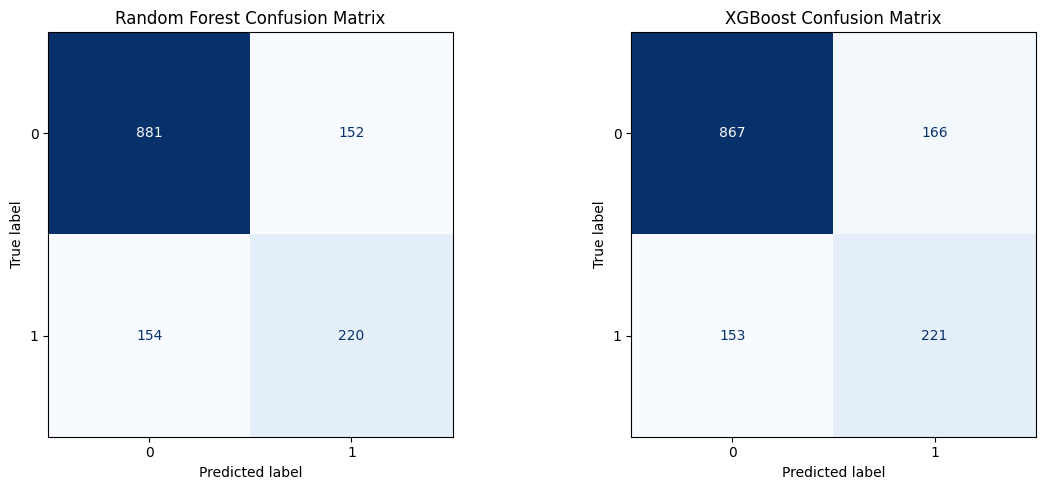

In [16]:
# --- 2. Confusion Matrices (Required Deliverable) ---
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
ConfusionMatrixDisplay.from_predictions(y_test, rf_model.predict(X_test_processed), ax=axes[0], cmap='Blues', colorbar=False)
axes[0].set_title('Random Forest Confusion Matrix')

ConfusionMatrixDisplay.from_predictions(y_test, xgb_model.predict(X_test_processed), ax=axes[1], cmap='Blues', colorbar=False)
axes[1].set_title('XGBoost Confusion Matrix')
plt.tight_layout()
plt.show()

In [17]:
# --- 3. Top 10 Feature Importances (XGBoost) ---
cat_feature_names = preprocessor.named_transformers_['cat'].get_feature_names_out(cat_cols)
all_feature_names = np.concatenate([num_cols, cat_feature_names])

/tmp/ipykernel_972/1381884526.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=importances, x='Importance', y='Feature', palette='viridis')


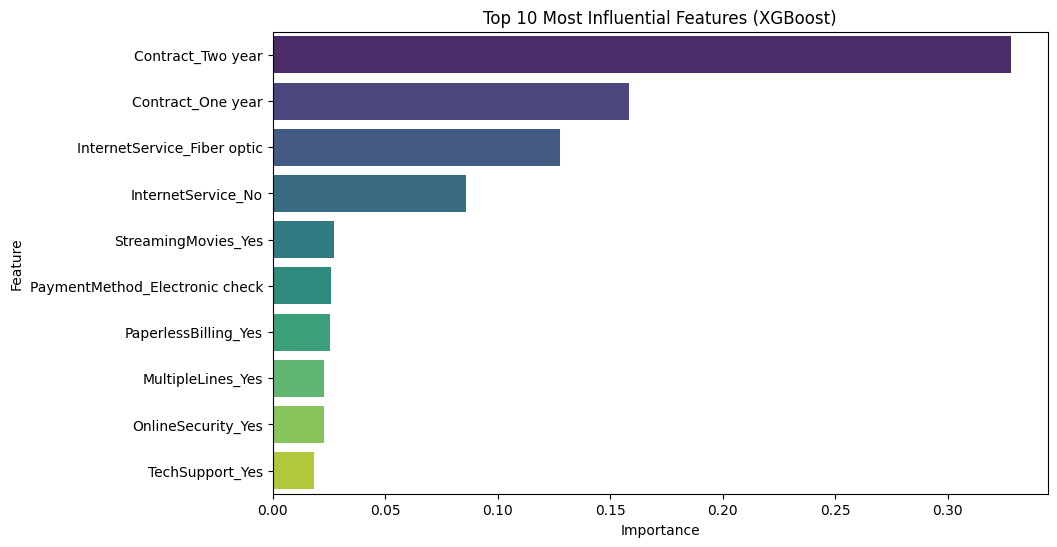

In [18]:
importances = pd.DataFrame({
    'Feature': all_feature_names,
    'Importance': xgb_model.feature_importances_
}).sort_values(by='Importance', ascending=False).head(10)

plt.figure(figsize=(10, 6))
sns.barplot(data=importances, x='Importance', y='Feature', palette='viridis')
plt.title('Top 10 Most Influential Features (XGBoost)')
plt.show()